In [1]:
!pip install -q implicit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 51.6 MB/s eta 0:00:00


### Data Processing

In [2]:
import urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp

urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-100k.zip", "ml-100k.zip")
with zipfile.ZipFile("ml-100k.zip") as z:
    z.extractall(".")
DATA = "ml-100k"

ratings = pd.read_csv(f"{DATA}/u.data", sep="\t",
                      names=["user_id", "item_id", "rating", "timestamp"])
users = pd.read_csv(f"{DATA}/u.user", sep="|",
                    names=["user_id", "age", "gender", "occupation", "zip"], encoding="latin-1")

genre_cols = ["unknown", "Action", "Adventure", "Animation", "Children", "Comedy", "Crime",
              "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery",
              "Romance", "Sci-Fi", "Thriller", "War", "Western"]
items = pd.read_csv(f"{DATA}/u.item", sep="|", encoding="latin-1",
                    names=["item_id", "title", "release_date", "video_release", "imdb_url"] + genre_cols)

print(f"Ratings: {len(ratings):,} | Users: {users.shape[0]} | Movies: {items.shape[0]}")

Ratings: 100,000 | Users: 943 | Movies: 1682


### Exploratory Analysis

Matrix sparsity: 93.70%


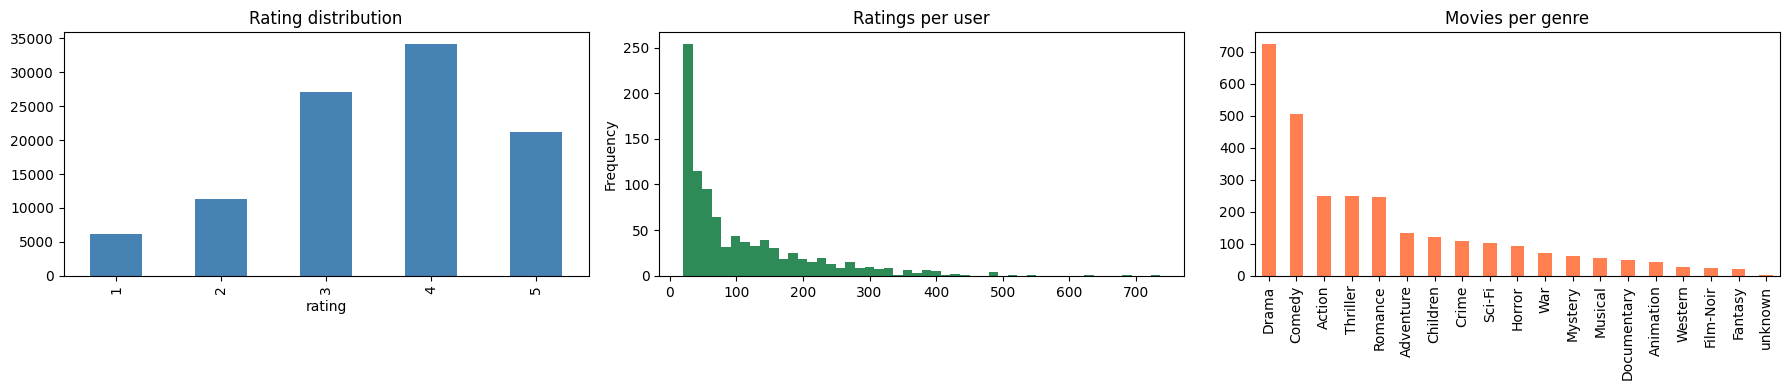

In [3]:
sparsity = 1 - len(ratings) / (ratings.user_id.nunique() * ratings.item_id.nunique())
print(f"Matrix sparsity: {sparsity:.2%}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ratings["rating"].value_counts().sort_index().plot.bar(ax=ax[0], title="Rating distribution", color="steelblue")
ratings.groupby("user_id").size().plot.hist(bins=50, ax=ax[1], title="Ratings per user", color="seagreen")
items[genre_cols].sum().sort_values(ascending=False).plot.bar(ax=ax[2], title="Movies per genre", color="coral")
plt.tight_layout(); plt.show()

In [4]:
# Map raw IDs to contiguous indices
user_ids = np.sort(ratings.user_id.unique())
item_ids = np.sort(items.item_id.unique())
user_idx = {u: i for i, u in enumerate(user_ids)}
item_idx = {m: i for i, m in enumerate(item_ids)}
idx_item = {i: m for m, i in item_idx.items()}
titles = items.set_index("item_id")["title"].to_dict()

positive = ratings[ratings.rating >= 4]
rows = positive.user_id.map(user_idx).values
cols = positive.item_id.map(item_idx).values
user_item = sp.csr_matrix((np.ones(len(positive)), (rows, cols)),
                          shape=(len(user_ids), len(item_ids)))
print(f"Positive interactions: {user_item.nnz:,} | Shape: {user_item.shape}")

Positive interactions: 55,375 | Shape: (943, 1682)


In [5]:
rng = np.random.RandomState(42)

def split_per_user(matrix, test_frac=0.2, seed=42):
    rng = np.random.RandomState(seed)
    train_rows, train_cols, test_rows, test_cols = [], [], [], []
    matrix = matrix.tocsr()
    for u in range(matrix.shape[0]):
        items_u = matrix[u].indices
        if len(items_u) < 5:          # too few positives: keep all in train
            train_rows += [u] * len(items_u); train_cols += list(items_u)
            continue
        rng.shuffle(items_u)
        n_test = max(1, int(len(items_u) * test_frac))
        test_items, train_items = items_u[:n_test], items_u[n_test:]
        train_rows += [u] * len(train_items); train_cols += list(train_items)
        test_rows += [u] * len(test_items);   test_cols += list(test_items)
    shape = matrix.shape
    train = sp.csr_matrix((np.ones(len(train_rows)), (train_rows, train_cols)), shape=shape)
    test = sp.csr_matrix((np.ones(len(test_rows)), (test_rows, test_cols)), shape=shape)
    return train, test

train, test = split_per_user(user_item)
print(f"Train: {train.nnz:,} | Test: {test.nnz:,}")

Train: 44,679 | Test: 10,696


In [6]:
items["year"] = pd.to_datetime(items.release_date, format="%d-%b-%Y", errors="coerce").dt.year
items["decade"] = (items.year // 10 * 10).fillna(0).astype(int)
decades = sorted(items.decade.unique())
decade_onehot = pd.get_dummies(items.decade).reindex(columns=decades, fill_value=0).astype(float)

item_content = np.hstack([items[genre_cols].values.astype(float), decade_onehot.values])
# Align rows to item_idx order (items sorted by item_id)
order = items.item_id.map(item_idx).values
aligned = np.zeros_like(item_content)
aligned[order] = item_content
item_content = aligned

# Normalize rows so the content similarity is a cosine
norms = np.linalg.norm(item_content, axis=1, keepdims=True)
norms[norms == 0] = 1
item_content_norm = item_content / norms
print("Content feature matrix:", item_content.shape)

Content feature matrix: (1682, 28)


In [7]:
from implicit.bpr import BayesianPersonalizedRanking
from implicit.als import AlternatingLeastSquares

K = 10

def precision_recall_at_k(score_fn, train_m, test_m, k=K):
    """score_fn(user_index) -> score vector over items."""
    precs, recs = [], []
    train_csr, test_csr = train_m.tocsr(), test_m.tocsr()
    for u in range(test_csr.shape[0]):
        true = test_csr[u].indices
        if len(true) == 0:
            continue
        scores = score_fn(u).astype(float)
        scores[train_csr[u].indices] = -np.inf   # don't recommend what's already seen
        top = np.argpartition(-scores, k)[:k]
        top = top[np.argsort(-scores[top])]
        hits = len(set(top) & set(true))
        precs.append(hits / k)
        recs.append(hits / len(true))
    return np.mean(precs), np.mean(recs)

def popularity_scorer(train_m):
    pop = np.asarray(train_m.sum(axis=0)).ravel().astype(float)
    return lambda u: pop

p, r = precision_recall_at_k(popularity_scorer(train), train, test)
baseline = {"model": "Popularity baseline", f"precision@{K}": p, f"recall@{K}": r}
print(baseline)

{'model': 'Popularity baseline', 'precision@10': np.float64(0.11300639658848614), 'recall@10': np.float64(0.1124776901741384)}


In [10]:
def train_bpr(factors=64, lr=0.01, reg=0.01, iters=100, seed=42):
    m = BayesianPersonalizedRanking(factors=factors, learning_rate=lr,
                                    regularization=reg, iterations=iters,
                                    random_state=seed)
    m.fit(train, show_progress=False)   # implicit expects user-items, same as `train`
    return m

def cf_scorer(model, train_m):
    user_factors = model.user_factors
    item_factors = model.item_factors
    if hasattr(user_factors, "to_numpy"):
        user_factors, item_factors = user_factors.to_numpy(), item_factors.to_numpy()
    return lambda u: item_factors @ user_factors[u]

def hybrid_scorer(cf_fn, alpha=0.2):
    """alpha blends content similarity into the collaborative score."""
    def score(u, train_m=train):
        cf = cf_fn(u)
        seen = train.tocsr()[u].indices
        if len(seen) == 0:
            return cf
        profile = item_content_norm[seen].mean(axis=0)     # user taste in content space
        profile /= (np.linalg.norm(profile) + 1e-9)
        content = item_content_norm @ profile
        # Standardize both signals before blending so alpha is meaningful
        cf_z = (cf - cf.mean()) / (cf.std() + 1e-9)
        ct_z = (content - content.mean()) / (content.std() + 1e-9)
        return (1 - alpha) * cf_z + alpha * ct_z
    return score

bpr = train_bpr()
cf_fn = cf_scorer(bpr, train)
results = [baseline]

p, r = precision_recall_at_k(cf_fn, train, test)
results.append({"model": "BPR (collaborative only)", f"precision@{K}": p, f"recall@{K}": r})

hyb = hybrid_scorer(cf_fn, alpha=0.2)
p, r = precision_recall_at_k(hyb, train, test)
results.append({"model": "BPR + content (hybrid)", f"precision@{K}": p, f"recall@{K}": r})

comparison = pd.DataFrame(results).set_index("model").round(4)
comparison

,precision@10,recall@10
model,,
Popularity baseline,0.1130,0.1125
BPR (collaborative only),0.1422,0.1763
BPR + content (hybrid),0.1365,0.1679


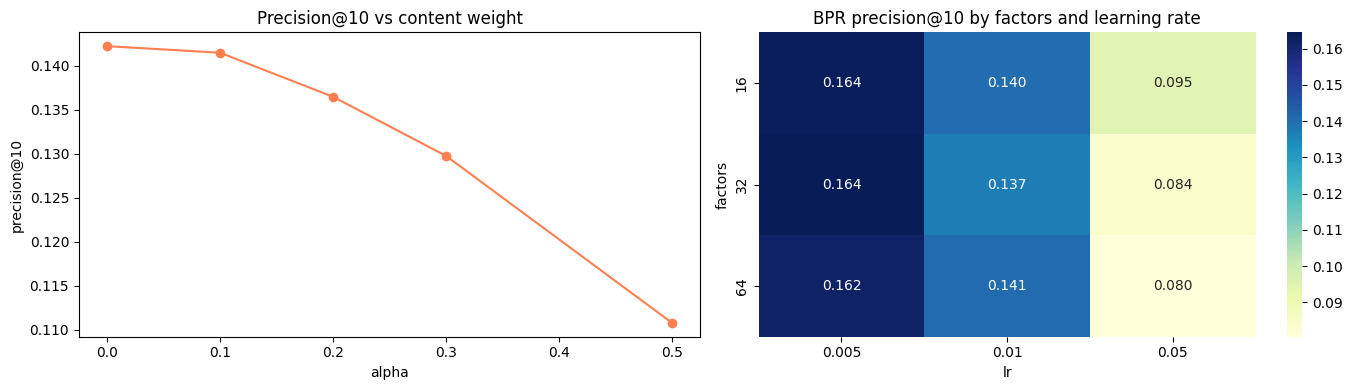

Best BPR config: {'factors': 32.0, 'lr': 0.005, 'precision': 0.164498933901919}


In [11]:
alphas = [0.0, 0.1, 0.2, 0.3, 0.5]
alpha_rows = []
for a in alphas:
    p, r = precision_recall_at_k(hybrid_scorer(cf_fn, alpha=a), train, test)
    alpha_rows.append({"content weight": a, f"precision@{K}": p, f"recall@{K}": r})
alpha_df = pd.DataFrame(alpha_rows)

grid = []
for factors in [16, 32, 64]:
    for lr in [0.005, 0.01, 0.05]:
        m = train_bpr(factors=factors, lr=lr)
        p, _ = precision_recall_at_k(cf_scorer(m, train), train, test)
        grid.append({"factors": factors, "lr": lr, "precision": p})
grid_df = pd.DataFrame(grid)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(alpha_df["content weight"], alpha_df[f"precision@{K}"], marker="o", color="coral")
ax[0].set(title="Precision@10 vs content weight", xlabel="alpha", ylabel="precision@10")
pivot = grid_df.pivot(index="factors", columns="lr", values="precision")
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax[1])
ax[1].set_title("BPR precision@10 by factors and learning rate")
plt.tight_layout(); plt.show()

best = grid_df.sort_values("precision", ascending=False).iloc[0]
print("Best BPR config:", best.to_dict())

In [12]:
final_bpr = train_bpr(factors=int(best.factors), lr=float(best.lr))
final_cf = cf_scorer(final_bpr, train)
best_alpha = alpha_df.sort_values(f"precision@{K}", ascending=False).iloc[0]["content weight"]
final_hybrid = hybrid_scorer(final_cf, alpha=best_alpha)

p, r = precision_recall_at_k(final_hybrid, train, test)
print(f"Final hybrid (alpha={best_alpha}): precision@{K}={p:.4f}, recall@{K}={r:.4f}")

Final hybrid (alpha=0.0): precision@10=0.1650, recall@10=0.1937


In [13]:
seen_by_user = ratings.groupby("user_id")["item_id"].apply(set).to_dict()

def recommend(user_id, n=10):
    u = user_idx[user_id]
    scores = final_hybrid(u)
    for iid in seen_by_user.get(user_id, []):
        scores[item_idx[iid]] = -np.inf
    top = np.argsort(-scores)[:n]
    return [titles[idx_item[i]] for i in top]

sample_user = 42
loved = (ratings[(ratings.user_id == sample_user) & (ratings.rating == 5)]
         .item_id.map(titles).head(5).tolist())
print("User 42 loved:", *loved, sep="\n  - ")
print("\nRecommended for user 42:", *recommend(sample_user), sep="\n  - ")

User 42 loved:
  - E.T. the Extra-Terrestrial (1982)
  - Terminator 2: Judgment Day (1991)
  - Sabrina (1995)
  - Beauty and the Beast (1991)
  - Terminator, The (1984)

Recommended for user 42:
  - Braveheart (1995)
  - Pretty Woman (1990)
  - Mrs. Doubtfire (1993)
  - Under Siege (1992)
  - Tombstone (1993)
  - Die Hard 2 (1990)
  - Home Alone (1990)
  - Die Hard: With a Vengeance (1995)
  - Die Hard (1988)
  - Crimson Tide (1995)


In [14]:
from sklearn.metrics.pairwise import cosine_similarity

item_emb = final_bpr.item_factors
if hasattr(item_emb, "to_numpy"):
    item_emb = item_emb.to_numpy()

def similar_movies(title_query, n=5):
    matches = items[items.title.str.contains(title_query, case=False, regex=False)]
    if matches.empty:
        return "Movie not found."
    idx = item_idx[matches.iloc[0].item_id]
    sims = cosine_similarity(item_emb[idx:idx+1], item_emb)[0]
    sims[idx] = -1
    top = np.argsort(-sims)[:n]
    return [(titles[idx_item[i]], round(float(sims[i]), 3)) for i in top]

print(similar_movies("Toy Story"))

[('Return of the Jedi (1983)', 0.839), ('Men in Black (1997)', 0.736), ('Star Trek: First Contact (1996)', 0.732), ('Independence Day (ID4) (1996)', 0.707), ('Hunchback of Notre Dame, The (1996)', 0.693)]


In [15]:
import pickle
artifacts = {
    "user_factors": final_bpr.user_factors,
    "item_factors": final_bpr.item_factors,
    "item_content_norm": item_content_norm,
    "train": train,
    "best_alpha": float(best_alpha),
    "user_idx": user_idx,
    "item_idx": item_idx,
    "idx_item": idx_item,
    "titles": titles,
    "seen": seen_by_user,
}
# Convert factors to numpy in case implicit returned GPU-style arrays
for k in ("user_factors", "item_factors"):
    if hasattr(artifacts[k], "to_numpy"):
        artifacts[k] = artifacts[k].to_numpy()

with open("movielens_implicit.pkl", "wb") as f:
    pickle.dump(artifacts, f)

from google.colab import files
files.download("movielens_implicit.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>